#### INF201 - Deliverable 1

**Group:** G4_1  
**Students:** Elias Bergset and Gayasha Lamahewa

Weather data from the Norwegian Meteorological Institute (Frost API).


#### Import Libraries

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import yaml

#### Client Id
Read Client ID from a separate file. This keeps the ID outside the submitted code.

In [ ]:
with open("client_id.txt", "r", encoding="utf-8") as file:
    client_id = file.read().strip()

#### Task 1 - Temperature
Get daily mean air temperature from Ås for 2025 and plot it by date.

In [ ]:
# Reference: https://frost.met.no/python_example.html
# The Frost API address where we get the weather observations.
endpoint = "https://frost.met.no/observations/v0.jsonld"
# Choose the weather station, daily mean temperature, and year 2025.
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}
# Send the request using the Client ID from our text file.
response = requests.get(endpoint, params=parameters, auth=(client_id, ""))
# Stop the code if the API request was not successful.
response.raise_for_status()
# Convert the response into data we can work with in Python.
json_data = response.json()
# Create an empty list for the observations.
rows = []
# Go through the observations and save the dates and temperatures.
for item in json_data["data"]:
    for observation in item["observations"]:
        rows.append({"referenceTime": item["referenceTime"],
                     "value": observation["value"]})
# Put the observations into a pandas DataFrame.
df = pd.DataFrame(rows)
# Convert the dates to datetime so the graph uses real dates.
df["referenceTime"] = pd.to_datetime(df["referenceTime"])
# Sort the observations by date.
df = df.sort_values("referenceTime")

#### Temperature Plot

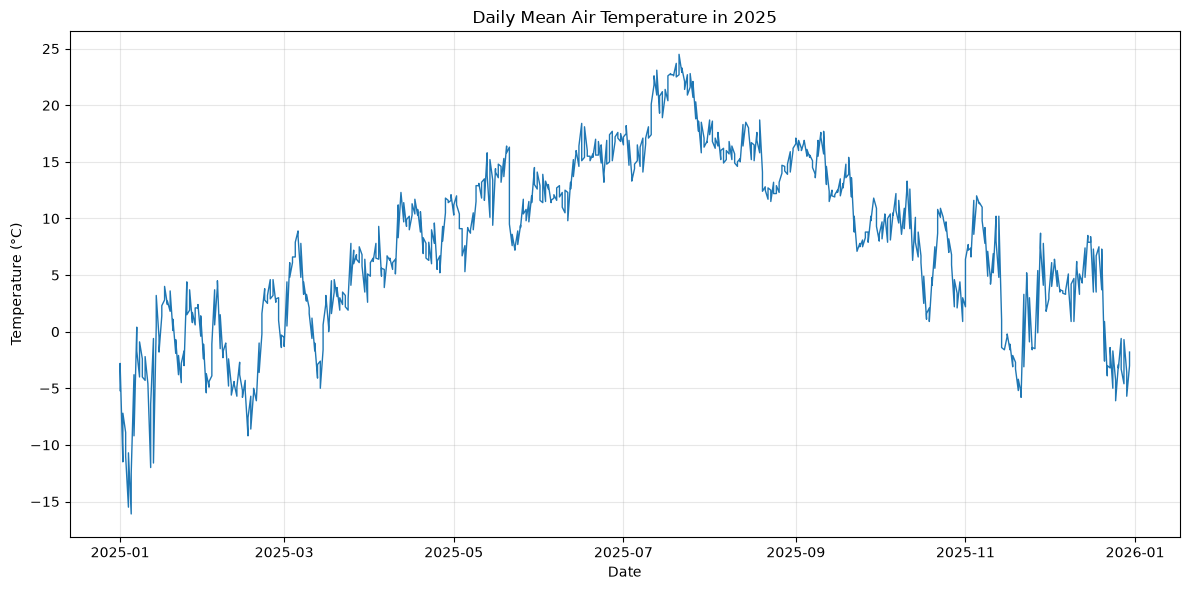

In [ ]:
# Create a figure for the temperature graph.
plt.figure(figsize=(12, 6))
# Show the daily mean temperature as a line.
plt.plot(df["referenceTime"], df["value"], linewidth=1)
# Add a title and labels to make the graph easier to read.
plt.title("Daily Mean Air Temperature in 2025")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
# Add a light grid to make the values easier to see.
plt.grid(True, alpha=0.3)
# Adjust the spacing before displaying the graph.
plt.tight_layout()
plt.show()

#### Summary Statistics

In [ ]:
# Calculate the mean, median, lowest and highest temperature.
summary = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum"],
    "Temperature (°C)": [df["value"].mean(), df["value"].median(),
                          df["value"].min(), df["value"].max()]
})
# Print the results as a simple summary table.
print(summary.to_string(index=False))

Statistic  Temperature (°C)
     Mean          7.903571
   Median          8.350000
  Minimum        -16.100000
  Maximum         24.500000


#### Task 2 - Precipitation
Plot 2025 daily precipitation and mean temperature on the same dates.

#### Choice of Graphs

**1. Line graph – Temperature**

Temperature changes continuously over time. A line makes it easy to see warming, cooling, and seasonal trends.

**2. Bar chart – Precipitation**

Precipitation is measured as an amount of rainfall, usually in millimetres (mm). Bars make it easy to identify rainy days and compare rainfall amounts.


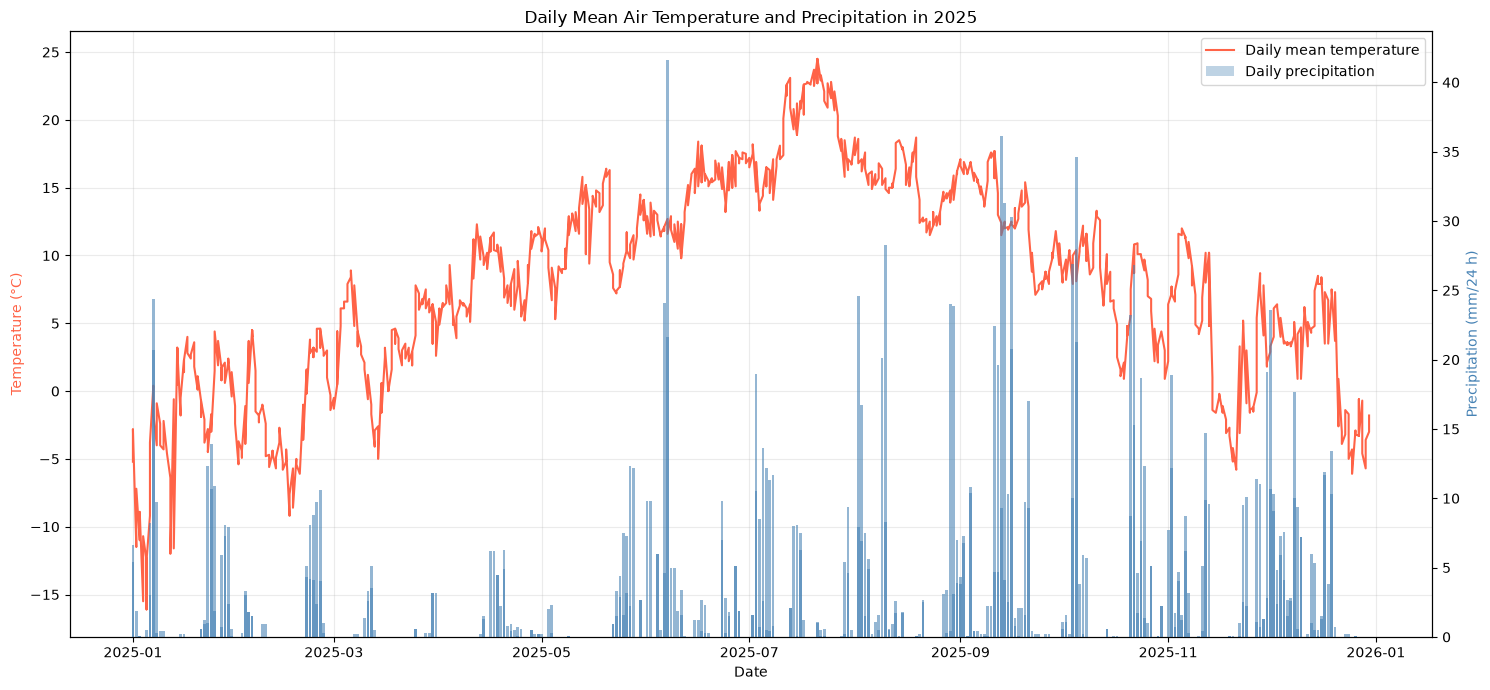

In [ ]:
# Request daily precipitation from Ås for the same year.
parameters = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31"
}
# Get the precipitation observations from Frost API.
response = requests.get(endpoint, params=parameters, auth=(client_id, ""))
response.raise_for_status()
# Make an empty list to store the precipitation data.
precipitation_rows = []
# Go through each observation and save the date and precipitation.
for item in response.json()["data"]:
    for observation in item["observations"]:
        precipitation_rows.append({
            "referenceTime": item["referenceTime"],
            "precipitation": observation["value"]
        })
# Convert the precipitation values into a DataFrame.
precipitation_df = pd.DataFrame(precipitation_rows)
# Convert the dates to datetime so they match the temperature dates.
precipitation_df["referenceTime"] = pd.to_datetime(
# Convert the dates to datetime so they match the temperature dates.
    precipitation_df["referenceTime"])
# Keep the dates and temperature values from Task 1.
temperature_df = df[["referenceTime", "value"]].rename(
    columns={"value": "temperature"})
# Combine temperature and precipitation using the dates.
combined_df = pd.merge(temperature_df, precipitation_df,
                       on="referenceTime", how="outer")
# Sort the combined data by date.
combined_df = combined_df.sort_values("referenceTime")
# Create the graph with one axis for temperature.
fig, ax1 = plt.subplots(figsize=(15, 7))
# Plot temperature as a line.
ax1.plot(combined_df["referenceTime"], combined_df["temperature"],
         color="tomato", linewidth=1.5, label="Daily mean temperature")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="tomato")
ax1.grid(True, alpha=0.25)
# Add a second axis for precipitation.
ax2 = ax1.twinx()
# Show daily precipitation as bars.
ax2.bar(combined_df["referenceTime"], combined_df["precipitation"],
        color="steelblue", alpha=0.35, width=0.8,
        label="Daily precipitation")
ax2.set_ylabel("Precipitation (mm/24 h)", color="steelblue")
plt.title("Daily Mean Air Temperature and Precipitation in 2025")
# Get the labels from both axes for one legend.
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
# Show both measurements in the legend.
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
fig.tight_layout()
plt.show()

#### Task 3 - Historical Temperature Data
Compare daily mean temperature in 1925 and 2025, aligned by month and day.

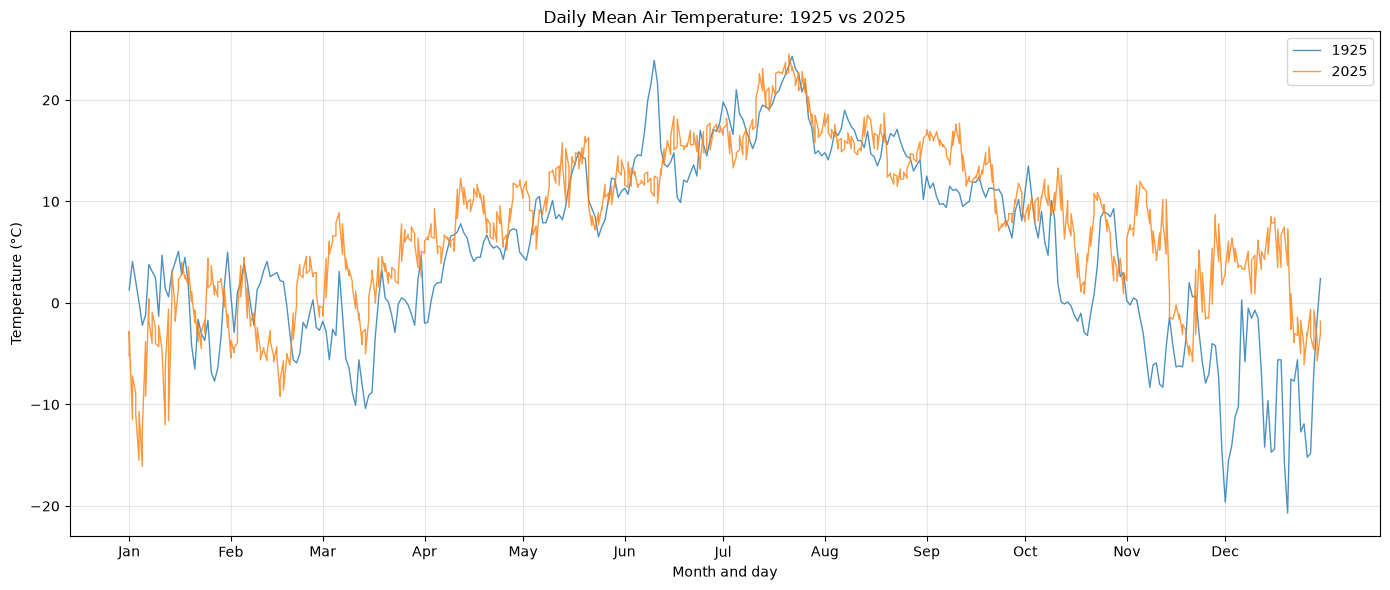

In [ ]:
# Request daily mean temperatures from 1925.
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1925-12-31"
}
# Send the request to Frost API.
response = requests.get(endpoint, params=parameters, auth=(client_id, ""))
response.raise_for_status()
# Store the historical observations in a list.
old_rows = []
# Go through the historical observations and save the values.
for item in response.json()["data"]:
    for observation in item["observations"]:
        old_rows.append({"referenceTime": item["referenceTime"],
                         "value": observation["value"]})
# Create a DataFrame with the temperatures from 1925.
old_df = pd.DataFrame(old_rows)
# Convert the old dates to datetime.
old_df["referenceTime"] = pd.to_datetime(old_df["referenceTime"])
# Create a DataFrame with the temperatures from 1925.
old_df = old_df.sort_values("referenceTime")
# Keep only month and day so we can compare both years.
df["month_day"] = df["referenceTime"].dt.strftime("%m-%d")
old_df["month_day"] = old_df["referenceTime"].dt.strftime("%m-%d")
# Create a figure for the historical comparison.
plt.figure(figsize=(14, 6))
# Plot the daily temperatures from 1925.
plt.plot(old_df["month_day"], old_df["value"],
         label="1925", linewidth=1, alpha=0.8)
# Plot the daily temperatures from 2025 on the same graph.
plt.plot(df["month_day"], df["value"],
         label="2025", linewidth=1, alpha=0.8)
plt.title("Daily Mean Air Temperature: 1925 vs 2025")
plt.xlabel("Month and day")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
# Choose one tick for each month on the x-axis.
month_ticks = [f"{i:02d}-01" for i in range(1, 13)]
# Display month names instead of full dates.
plt.xticks(month_ticks, ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.tight_layout()
plt.show()

#### Summary Statistics

In [ ]:
# Compare mean, median, minimum and maximum temperatures for both years.
summary = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum"],
    "1925 (°C)": [old_df["value"].mean(), old_df["value"].median(),
                  old_df["value"].min(), old_df["value"].max()],
    "2025 (°C)": [df["value"].mean(), df["value"].median(),
                  df["value"].min(), df["value"].max()]
})
# Print the comparison table with two decimal places.
print(summary.round(2).to_string(index=False))

Statistic  1925 (°C)  2025 (°C)
     Mean       5.31       7.90
   Median       5.30       8.35
  Minimum     -20.70     -16.10
  Maximum      24.30      24.50


#### Task 4 - Heatwaves
In this task we find heatwaves in Ås in 2025. A heatwave is 5 or more days in a row with a maximum temperature of at least 27 degrees.

#### Create A Function To Find Heatwaves

In [ ]:
def count_heatwaves(station, year):
    # Parameters for maximum daily temperature.
    heatwave_parameters = {
        "sources": station,
        "elements": "max(air_temperature P1D)",
        "referencetime": f"{year}-01-01/{year + 1}-01-01"
    }
    # Get data from Frost API.
    response = requests.get(
        endpoint,
        params=heatwave_parameters,
        auth=(client_id, "")
    )
    # Check if the request was successful.
    print("Status code:", response.status_code)
    response.raise_for_status()
    # Convert the response to Python data.
    heatwave_json = response.json()
    # Create a list for dates and temperatures.
    dates = []
    temperatures = []
    # Go through all observations.
    for item in heatwave_json["data"]:
        date = item["referenceTime"]
        for observation in item["observations"]:
            temperature = observation["value"]
            dates.append(date)
            temperatures.append(temperature)
    # CREATE A TABLE
    # Create a DataFrame.
    heatwave_data = pd.DataFrame({
        "Date": dates,
        "Temperature": temperatures
    })
    # Convert dates to datetime.
    heatwave_data["Date"] = pd.to_datetime(
        heatwave_data["Date"],
        utc=True
    ).dt.date
    # Use one maximum temperature for each day.
    heatwave_data = heatwave_data.groupby(
        "Date"
    )["Temperature"].max()

    # Add all calendar days.
    # Missing days will not count as hot days.
    all_dates = pd.date_range(
        f"{year}-01-01",
        f"{year}-12-31"
    ).date
    heatwave_data = heatwave_data.reindex(all_dates)
    # FIND HEATWAVES
    # Create an empty list for heatwaves.
    heatwaves = []
    # Count days with high temperature.
    days = 0
    start_date = None
    # Go through all dates and temperatures.
    for date, temperature in heatwave_data.items():
        # Check if the temperature is 27 or higher.
        if temperature >= 27:
            # Save the first day.
            if days == 0:
                start_date = date
            days += 1
        else:
            # Check if we had at least 5 hot days.
            if days >= 5:
                # Save the heatwave period.

                heatwaves.append(
                    f"{start_date} - {previous_date}"
                )
            # Reset the counter.
            days = 0
        # Save the current date.
        previous_date = date
    # Check the last days of the year.
    if days >= 5:
        heatwaves.append(
            f"{start_date} - {previous_date}"
        )
    # SAVE RESULTS TO YAML
    # Get the station name from Frost API.
    station_response = requests.get(
        "https://frost.met.no/sources/v0.jsonld",
        params={"ids": station},
        auth=(client_id, "")
    )
    station_response.raise_for_status()
    station_data = station_response.json()
    # Get the station name.
    station_name = station_data["data"][0]["name"]
    # Create a summary like the example file.
    heatwave_summary = {
        "dates": heatwaves,
        "station_id": station,
        "station_name": station_name,
        "year": year
    }
    # Save the summary to a YAML file.
    with open("heatwave_summary.yml", "w", encoding="utf-8") as file:
        yaml.safe_dump(
            heatwave_summary,
            file,
            sort_keys=False
        )
    # Print the results.
    print("\nHeatwave summary:")
    print("Station:", station_name)
    print("Year:", year)
    print("Number of heatwaves:", len(heatwaves))
    print("Heatwaves:", heatwaves)
    return len(heatwaves)

#### Run The Function
Find heatwaves in Ås in 2025.

In [ ]:
count_heatwaves("SN17850", 2025)

Status code: 200

Heatwave summary:
Station: ÅS
Year: 2025
Number of heatwaves: 1
Heatwaves: ['2025-07-16 - 2025-07-22']


1

#### Task 5 - Moving Average Temperature
In this task we calculate the 7-day moving average. We use the daily mean temperatures from Task 1.

#### Create A Function For Moving Average

In [ ]:
def calculate_moving_average(data):
    # Make a copy of the temperature data.
    moving_data = data.copy()
    # Convert dates to datetime.
    moving_data["Date"] = pd.to_datetime(
        moving_data["Date"],
        utc=True
    )
    # Use one mean temperature for each day.
    moving_data = moving_data.groupby(
        "Date", as_index=False
    )["Temperature"].mean()
    # Sort the data by date.
    moving_data = moving_data.sort_values("Date")
    # Use dates as the index.
    moving_data = moving_data.set_index("Date")
    # Add missing calendar dates.
    # Missing temperatures will be NaN.
    moving_data = moving_data.asfreq("D")
    # Calculate the 7-day moving average.
    moving_data["Moving Average"] = (
        moving_data["Temperature"].rolling(
            window=7,
            min_periods=7
        ).mean()
    )
    # Return the data with the moving average.
    return moving_data

#### Calculate Moving Average For 2025
Use the temperature data from Task 1. The data is formatted into the Date and Temperature columns used by the original function.

In [ ]:
temperature_data = df[["referenceTime", "value"]].rename(
    columns={"referenceTime": "Date", "value": "Temperature"}
)
moving_average_data = calculate_moving_average(
    temperature_data
)
# Show the first 10 rows.
print("\n7-day moving average:")
print(moving_average_data.head(10))


7-day moving average:
                           Temperature  Moving Average
Date                                                  
2025-01-01 00:00:00+00:00        -4.00             NaN
2025-01-02 00:00:00+00:00        -9.35             NaN
2025-01-03 00:00:00+00:00        -9.95             NaN
2025-01-04 00:00:00+00:00       -13.10             NaN
2025-01-05 00:00:00+00:00       -14.30             NaN
2025-01-06 00:00:00+00:00        -6.50             NaN
2025-01-07 00:00:00+00:00        -0.65       -8.264286
2025-01-08 00:00:00+00:00        -2.45       -8.042857
2025-01-09 00:00:00+00:00        -3.20       -7.164286
2025-01-10 00:00:00+00:00        -3.25       -6.207143


#### Create A Graph

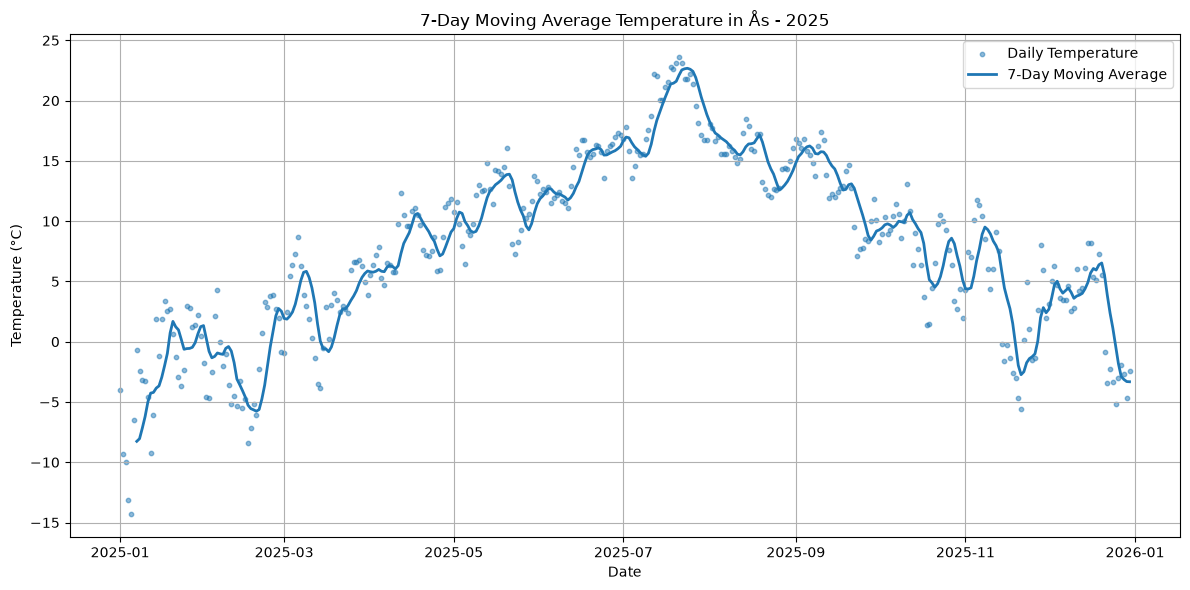

In [ ]:
plt.figure(figsize=(12, 6))
# Show daily temperature as points.
plt.scatter(
    moving_average_data.index,
    moving_average_data["Temperature"],
    label="Daily Temperature",
    s=10,
    alpha=0.5
)
# Show the 7-day moving average as a line.
plt.plot(
    moving_average_data.index,
    moving_average_data["Moving Average"],
    label="7-Day Moving Average",
    linewidth=2
)
# Add a title.
plt.title("7-Day Moving Average Temperature in Ås - 2025")
# Add labels to the axes.
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
# Add a legend.
plt.legend()
# Add a grid.
plt.grid(True)
# Make sure everything fits in the figure.
plt.tight_layout()
# Show the graph.
plt.show()


#### Discussion of Results

**Task 1 – Temperature**

The temperature graph shows how the temperature changes throughout 2025. We can see that the temperatures are lowest during winter and highest during summer, especially in July.

The summary statistics show a mean temperature of approximately 7.9°C and a median of 8.35°C. The lowest recorded temperature was -16.1°C, while the highest was 24.5°C.

**Task 2 – Precipitation**

The graph shows both temperature and precipitation during 2025. We used a line graph for temperature and bars for precipitation.

We can see that precipitation varies throughout the year, with some days having much more rainfall than others. Using two different y-axes makes it easier to compare the measurements.

**Task 3 – Historical Temperature**

In this task, we compared temperatures from 1925 and 2025.

The average temperature was 5.31°C in 1925 and 7.90°C in 2025. This means that 2025 was approximately 2.59°C warmer on average.

The graph also shows differences between the two years, especially during the colder months. However, comparing only two years is not enough to determine a long-term climate trend.

**Task 4 – Heatwaves**

We used daily maximum temperatures to identify heatwaves. A heatwave was defined as at least five consecutive days with temperatures of 27°C or higher.

Our results showed one heatwave in 2025. The function also saves the results in a YAML file.

**Task 5 – Moving Average**

We calculated a 7-day moving average of the daily mean temperature.

The moving average line is smoother than the original daily temperatures because it reduces short-term variations.

This makes it easier to see the general temperature trend throughout the year.

**Conclusion**

The assignment helped us understand how to collect and analyse weather data using Python. We also learned how different graphs can be used to present data and how summary statistics can help us understand the results.




#### GitHub Repository

Our GitHub repository:

https://github.com/minibergset/git-practice


#### Use of AI Tools

During this assignment, we used AI tools to help us understand parts of the Python code and improve the presentation of our graphs. The AI tools were useful for explaining different approaches to solving problems and helping us understand how certain functions work.

We also used AI tools to get suggestions for improving our code and solving some programming errors. We reviewed the suggestions and made sure they were relevant to the assignment.